In [1]:
import sys
from pathlib import Path
ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

In [2]:
import SimpleITK as sitk
import matplotlib.pyplot as plt
import pandas as pd
from scipy.ndimage import center_of_mass

from lib import *

In [3]:
manifest_path = "/home/furkan/projects/mebar-radiology/data/manifest.csv"
manifest_df = pd.read_csv(manifest_path)

# Crop Volume Analysis

## 1. Narrowest Rectangular Prism
First of all we should analyze the distribution of dimensions of each tumor volume, x-y-z in millimeters. Below we calculate the narrowest rectangular prism for each tumor, length of dimensions, coordinates of center and save them to anew df.

In [4]:
tumor_volume_analysis_df = manifest_df[[
    "sample_id",
    "modality",
    "image_path",
    "mask_path",
    "image_shape_x",
    "image_shape_y",
    "image_shape_z",
    "image_spacing_x_mm",
    "image_spacing_y_mm",
    "image_spacing_z_mm",
    "mask_shape_x",
    "mask_shape_y",
    "mask_shape_z",
    "mask_spacing_x_mm",
    "mask_spacing_y_mm",
    "mask_spacing_z_mm",
]]

In [5]:
x_voxel_interval = []
y_voxel_interval = []
z_voxel_interval = []
mm_lps_centers = []
x_mm_len = []
y_mm_len = []
z_mm_len = []

for idx, row in tumor_volume_analysis_df.iterrows():
    mask_path = get_abs_path(row["mask_path"])
    mask_image = sitk.ReadImage(mask_path)
    stats = sitk.LabelShapeStatisticsImageFilter()
    stats.Execute(mask_image)

    # voxel labels
    tissue = 0
    tumor = 1

    bbox = stats.GetBoundingBox(tumor)
    start_x, start_y, start_z, size_x, size_y, size_z = bbox

    # fill voxel intervals
    x_voxel_interval.append((start_x, start_x+size_x))
    y_voxel_interval.append((start_y, start_y+size_y))
    z_voxel_interval.append((start_z, start_z+size_z))

    # fill mm center coordinates
    voxel_center_xyz = (
        start_x + (size_x - 1) / 2.0,
        start_y + (size_y - 1) / 2.0,
        start_z + (size_z - 1) / 2.0
    )

    mm_lps_center = mask_image.TransformContinuousIndexToPhysicalPoint(voxel_center_xyz)
    mm_lps_centers.append(mm_lps_center)

    # fill mm lengths of dimensions
    spacing_x, spacing_y, spacing_z = mask_image.GetSpacing()

    x_mm_len.append(size_x * spacing_x)
    y_mm_len.append(size_y * spacing_y)
    z_mm_len.append(size_z * spacing_z)

tumor_volume_analysis_df["x_voxel_interval"] = x_voxel_interval
tumor_volume_analysis_df["y_voxel_interval"] = y_voxel_interval
tumor_volume_analysis_df["z_voxel_interval"] = z_voxel_interval

tumor_volume_analysis_df["mm_lps_centers"] = mm_lps_centers

tumor_volume_analysis_df["x_mm_len"] = x_mm_len
tumor_volume_analysis_df["y_mm_len"] = y_mm_len
tumor_volume_analysis_df["z_mm_len"] = z_mm_len

In [6]:
# total volume in mm also might be beneficial
tumor_volume_analysis_df["mm^3 volume"] = tumor_volume_analysis_df["x_mm_len"] * tumor_volume_analysis_df["y_mm_len"] * tumor_volume_analysis_df["z_mm_len"]

In [7]:
tumor_volume_analysis_df.head()

,sample_id,modality,image_path,mask_path,image_shape_x,image_shape_y,image_shape_z,image_spacing_x_mm,image_spacing_y_mm,image_spacing_z_mm,...,mask_spacing_y_mm,mask_spacing_z_mm,x_voxel_interval,y_voxel_interval,z_voxel_interval,mm_lps_centers,x_mm_len,y_mm_len,z_mm_len,mm^3 volume
0,0d6f73a01539ae0d,ADC,"data/raw/batch-1/INTERMEDIATE/ABDULLAEVA, GULS...","data/raw/batch-1/INTERMEDIATE/ABDULLAEVA, GULS...",224,224,45,1.785714,1.785714,6.600000,...,1.785714,6.600000,"(100, 117)","(127, 145)","(10, 17)","(12.146470841209037, 68.22208703707614, -150.9...",30.357143,32.142857,46.199998,45080.354563
1,85388bd87a565011,T2,"data/raw/batch-1/INTERMEDIATE/ABDULLAEVA, GULS...","data/raw/batch-1/INTERMEDIATE/ABDULLAEVA, GULS...",352,352,24,0.397727,0.397727,3.500000,...,0.397727,3.500000,"(130, 215)","(111, 197)","(9, 18)","(13.393192570796039, 64.13901366504405, -154.6...",33.806819,34.204546,31.499998,36424.925327
2,c5574c732708c9c0,ADC,"data/raw/batch-1/INTERMEDIATE/AKKAYA, HATICE/A...","data/raw/batch-1/INTERMEDIATE/AKKAYA, HATICE/A...",128,256,20,0.781250,0.781250,3.600031,...,0.781250,3.600031,"(37, 94)","(98, 148)","(3, 17)","(23.787239022978383, 89.20923187704231, -272.6...",44.531250,39.062500,50.400434,87671.653446
3,d4e511f387bc2059,T2,"data/raw/batch-1/INTERMEDIATE/AKKAYA, HATICE/T...","data/raw/batch-1/INTERMEDIATE/AKKAYA, HATICE/T...",336,336,20,0.595238,0.595238,3.600029,...,0.595238,3.600029,"(132, 206)","(125, 200)","(3, 19)","(23.292095442398008, 88.68616881738511, -268.9...",44.047612,44.642850,57.600468,113266.189781
4,85e3e9f712fe9029,ADC,"data/raw/batch-1/INTERMEDIATE/ARSLAN, AYSEL/AD...","data/raw/batch-1/INTERMEDIATE/ARSLAN, AYSEL/AD...",224,224,36,1.785714,1.785714,6.600000,...,1.785714,6.600000,"(112, 126)","(110, 127)","(12, 17)","(-0.9782674279655907, 44.64582249715505, -188....",25.000000,30.357143,32.999999,25044.641260


## 2. Distribution and Statistical Analysis
Min and max of each dimension will be our crop's dimensions, with a margin. However, I want to see the difference between samples. This will give us insights about the weak points of our dataset and might show us the path to choose the correct method.

### 2.1 Histogram of Each dimension

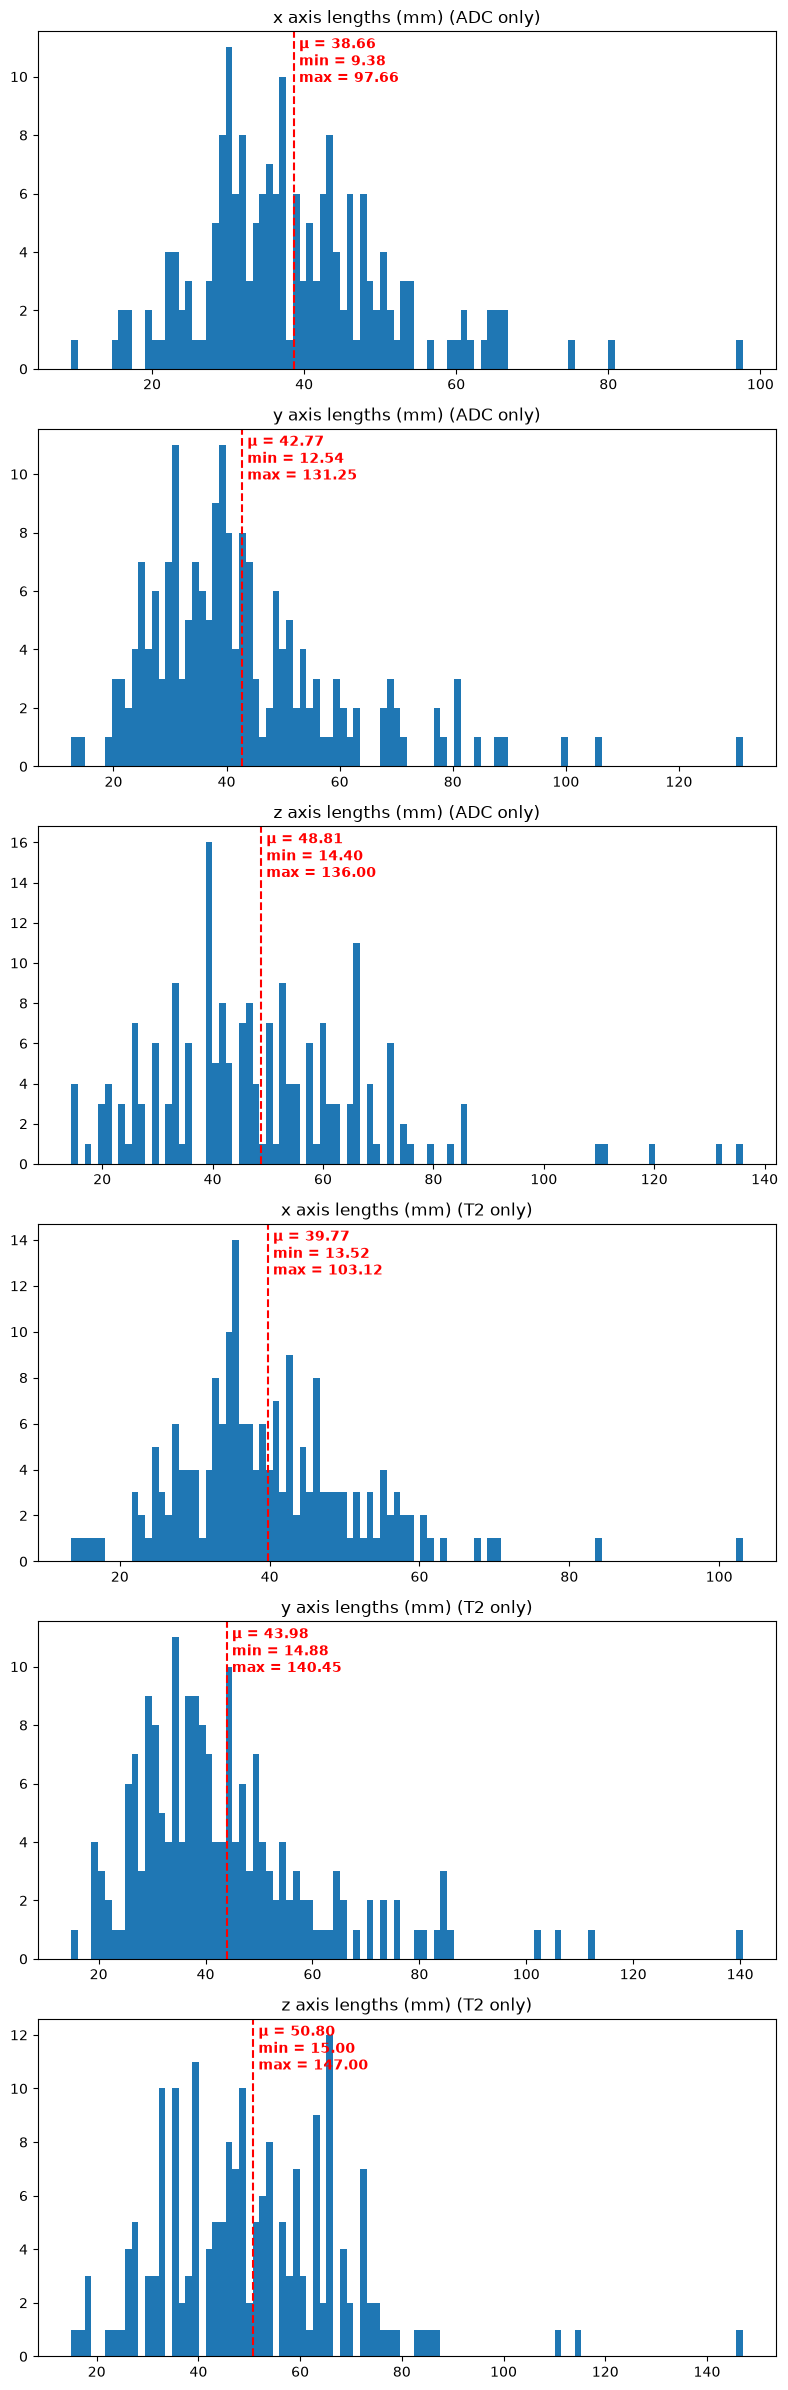

In [8]:
def plot_histograms(bins=100, means=True, filter_interval=None):
    fig, axes = plt.subplots(6, 1, figsize=(8, 24))

    stats_summary = {}

    # ADC
    adc_window = tumor_volume_analysis_df[
        tumor_volume_analysis_df["modality"] == "ADC"
    ]
    if filter_interval is not None:
        columns = ["x_mm_len", "y_mm_len", "z_mm_len"]
        for col in columns:
            q_low, q_high = adc_window[col].quantile([filter_interval[0], filter_interval[1]])
            up_drop = (adc_window[col] > q_high).sum()
            stats_summary.setdefault(("ADC", col[0]), {})["up_drop"] = up_drop
            adc_window[col] = adc_window[col][
                adc_window[col].between(q_low, q_high)
            ]

    axes[0].hist(adc_window["x_mm_len"], bins=bins)
    axes[0].set_title("x axis lengths (mm) (ADC only)")
    val_adc_x = adc_window["x_mm_len"].mean()
    mi_adc_x = adc_window["x_mm_len"].min()
    ma_adc_x = adc_window["x_mm_len"].max()
    stats_summary.setdefault(("ADC", "x"), {}).update({"mean": val_adc_x, "min": mi_adc_x, "max": ma_adc_x})
    if means:
        axes[0].axvline(val_adc_x, color="red", linestyle="--")
        axes[0].text(
            val_adc_x,
            axes[0].get_ylim()[1] * 0.85,
            f" µ = {val_adc_x:.2f}\n min = {mi_adc_x:.2f}\n max = {ma_adc_x:.2f}",
            color="red",
            fontweight="bold",
        )

    axes[1].hist(adc_window["y_mm_len"], bins=bins)
    axes[1].set_title("y axis lengths (mm) (ADC only)")
    val_adc_y = adc_window["y_mm_len"].mean()
    mi_adc_y = adc_window["y_mm_len"].min()
    ma_adc_y = adc_window["y_mm_len"].max()
    stats_summary.setdefault(("ADC", "y"), {}).update({"mean": val_adc_y, "min": mi_adc_y, "max": ma_adc_y})
    if means:
        axes[1].axvline(val_adc_y, color="red", linestyle="--")
        axes[1].text(
            val_adc_y,
            axes[1].get_ylim()[1] * 0.85,
            f" µ = {val_adc_y:.2f}\n min = {mi_adc_y:.2f}\n max = {ma_adc_y:.2f}",
            color="red",
            fontweight="bold",
        )

    axes[2].hist(adc_window["z_mm_len"], bins=bins)
    axes[2].set_title("z axis lengths (mm) (ADC only)")
    val_adc_z = adc_window["z_mm_len"].mean()
    mi_adc_z = adc_window["z_mm_len"].min()
    ma_adc_z = adc_window["z_mm_len"].max()
    stats_summary.setdefault(("ADC", "z"), {}).update({"mean": val_adc_z, "min": mi_adc_z, "max": ma_adc_z})
    if means:
        axes[2].axvline(val_adc_z, color="red", linestyle="--")
        axes[2].text(
            val_adc_z,
            axes[2].get_ylim()[1] * 0.85,
            f" µ = {val_adc_z:.2f}\n min = {mi_adc_z:.2f}\n max = {ma_adc_z:.2f}",
            color="red",
            fontweight="bold",
        )

    # T2
    t2_window = tumor_volume_analysis_df[
        tumor_volume_analysis_df["modality"] == "T2"
    ]
    if filter_interval is not None:
        columns = ["x_mm_len", "y_mm_len", "z_mm_len"]
        for col in columns:
            q_low, q_high = t2_window[col].quantile([filter_interval[0], filter_interval[1]])
            up_drop = (t2_window[col] > q_high).sum()
            stats_summary.setdefault(("T2", col[0]), {})["up_drop"] = up_drop
            t2_window[col] = t2_window[col][t2_window[col].between(q_low, q_high)]

    axes[3].hist(t2_window["x_mm_len"], bins=bins)
    axes[3].set_title("x axis lengths (mm) (T2 only)")
    val_t2_x = t2_window["x_mm_len"].mean()
    mi_t2_x = t2_window["x_mm_len"].min()
    ma_t2_x = t2_window["x_mm_len"].max()
    stats_summary.setdefault(("T2", "x"), {}).update({"mean": val_t2_x, "min": mi_t2_x, "max": ma_t2_x})
    if means:
        axes[3].axvline(val_t2_x, color="red", linestyle="--")
        axes[3].text(
            val_t2_x,
            axes[3].get_ylim()[1] * 0.85,
            f" µ = {val_t2_x:.2f}\n min = {mi_t2_x:.2f}\n max = {ma_t2_x:.2f}",
            color="red",
            fontweight="bold",
        )

    axes[4].hist(t2_window["y_mm_len"], bins=bins)
    axes[4].set_title("y axis lengths (mm) (T2 only)")
    val_t2_y = t2_window["y_mm_len"].mean()
    mi_t2_y = t2_window["y_mm_len"].min()
    ma_t2_y = t2_window["y_mm_len"].max()
    stats_summary.setdefault(("T2", "y"), {}).update({"mean": val_t2_y, "min": mi_t2_y, "max": ma_t2_y})
    if means:
        axes[4].axvline(val_t2_y, color="red", linestyle="--")
        axes[4].text(
            val_t2_y,
            axes[4].get_ylim()[1] * 0.85,
            f" µ = {val_t2_y:.2f}\n min = {mi_t2_y:.2f}\n max = {ma_t2_y:.2f}",
            color="red",
            fontweight="bold",
        )

    axes[5].hist(t2_window["z_mm_len"], bins=bins)
    axes[5].set_title("z axis lengths (mm) (T2 only)")
    val_t2_z = t2_window["z_mm_len"].mean()
    mi_t2_z = t2_window["z_mm_len"].min()
    ma_t2_z = t2_window["z_mm_len"].max()
    stats_summary.setdefault(("T2", "z"), {}).update({"mean": val_t2_z, "min": mi_t2_z, "max": ma_t2_z})
    if means:
        axes[5].axvline(val_t2_z, color="red", linestyle="--")
        axes[5].text(
            val_t2_z,
            axes[5].get_ylim()[1] * 0.85,
            f" µ = {val_t2_z:.2f}\n min = {mi_t2_z:.2f}\n max = {ma_t2_z:.2f}",
            color="red",
            fontweight="bold",
        )

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(stats_summary).T


stats_all_df = plot_histograms()

In [9]:
stats_all_df

mean        min         max
ADC x  38.664543   9.375000   97.656250
    y  42.774045  12.537280  131.249995
    z  48.814527  14.399947  136.000004
T2  x  39.774225  13.522728  103.125000
    y  43.984015  14.880950  140.454547
    z  50.801739  15.000000  147.000000

On the plots we clearly see that there are a couple outlier values. They are not many in numbers but too outlying too much in volume. We should analyze outliers excluded as well.

### 2.2 Histogram without Outliers

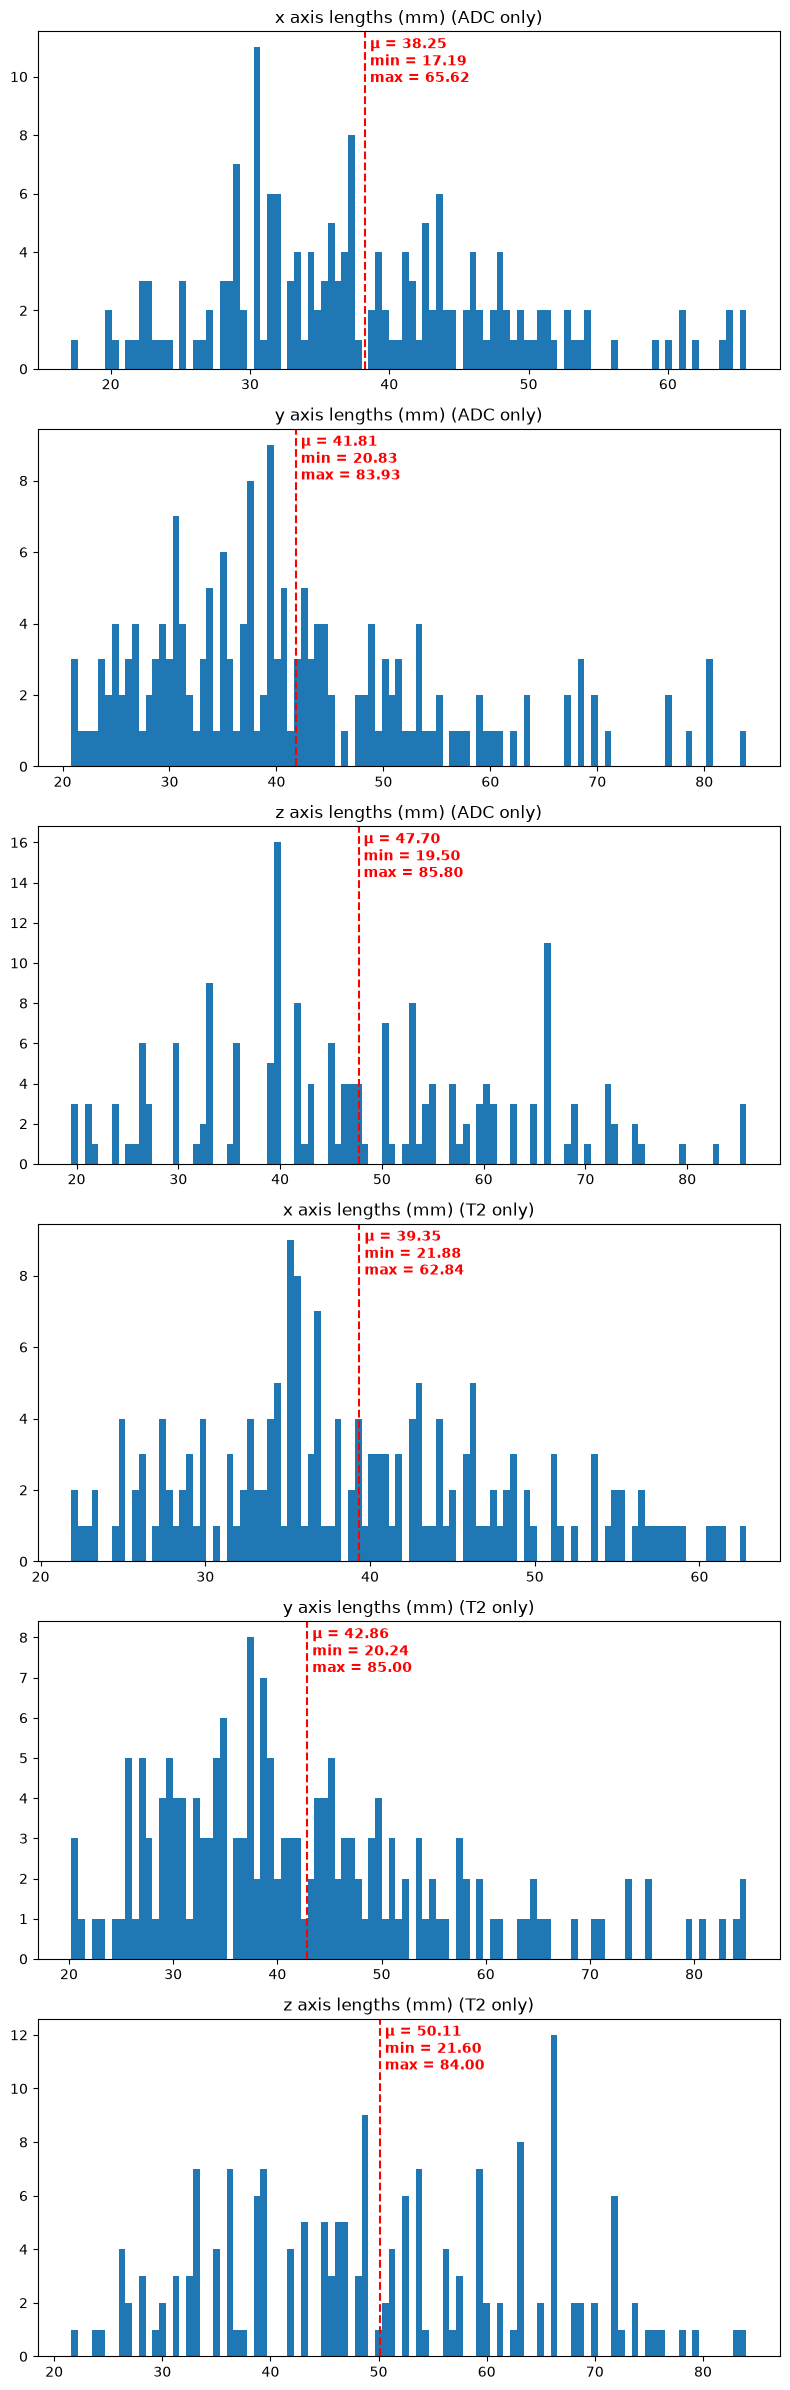

In [10]:
stats_no_outliers_df = plot_histograms(filter_interval=(0.025, 0.975))

In [11]:
stats_no_outliers_df

up_drop       mean        min        max
ADC x      5.0  38.251895  17.187500  65.625000
    y      5.0  41.805563  20.833333  83.928571
    z      5.0  47.704671  19.500034  85.800000
T2  x      5.0  39.353274  21.875000  62.840910
    y      5.0  42.864116  20.238092  84.999998
    z      5.0  50.109140  21.600020  84.000001

In [12]:
stats_combined_df = pd.concat(
    [stats_all_df, stats_no_outliers_df],
    axis=1,
    keys=["all", "filtered (p2.5 - p97.5)"]
)
stats_combined_df

all                        filtered (p2.5 - p97.5)             \
            mean        min         max                 up_drop       mean   
ADC x  38.664543   9.375000   97.656250                     5.0  38.251895   
    y  42.774045  12.537280  131.249995                     5.0  41.805563   
    z  48.814527  14.399947  136.000004                     5.0  47.704671   
T2  x  39.774225  13.522728  103.125000                     5.0  39.353274   
    y  43.984015  14.880950  140.454547                     5.0  42.864116   
    z  50.801739  15.000000  147.000000                     5.0  50.109140   

                             
             min        max  
ADC x  17.187500  65.625000  
    y  20.833333  83.928571  
    z  19.500034  85.800000  
T2  x  21.875000  62.840910  
    y  20.238092  84.999998  
    z  21.600020  84.000001

Mean almost not affected, however, min-max is affected drastically. For this case, max is what we care because we aim to crop all samples according to the max dimensions to fit all tumors into one specific volume. When outliers excluded, memory and computation lost will be decreased dramatically, and only 2.5% of the whole data (5 samples) will be negatively affected. In my opinion this is acceptable.

Also I wanted to see how many samples would be affected if we used a tighter upper limit:

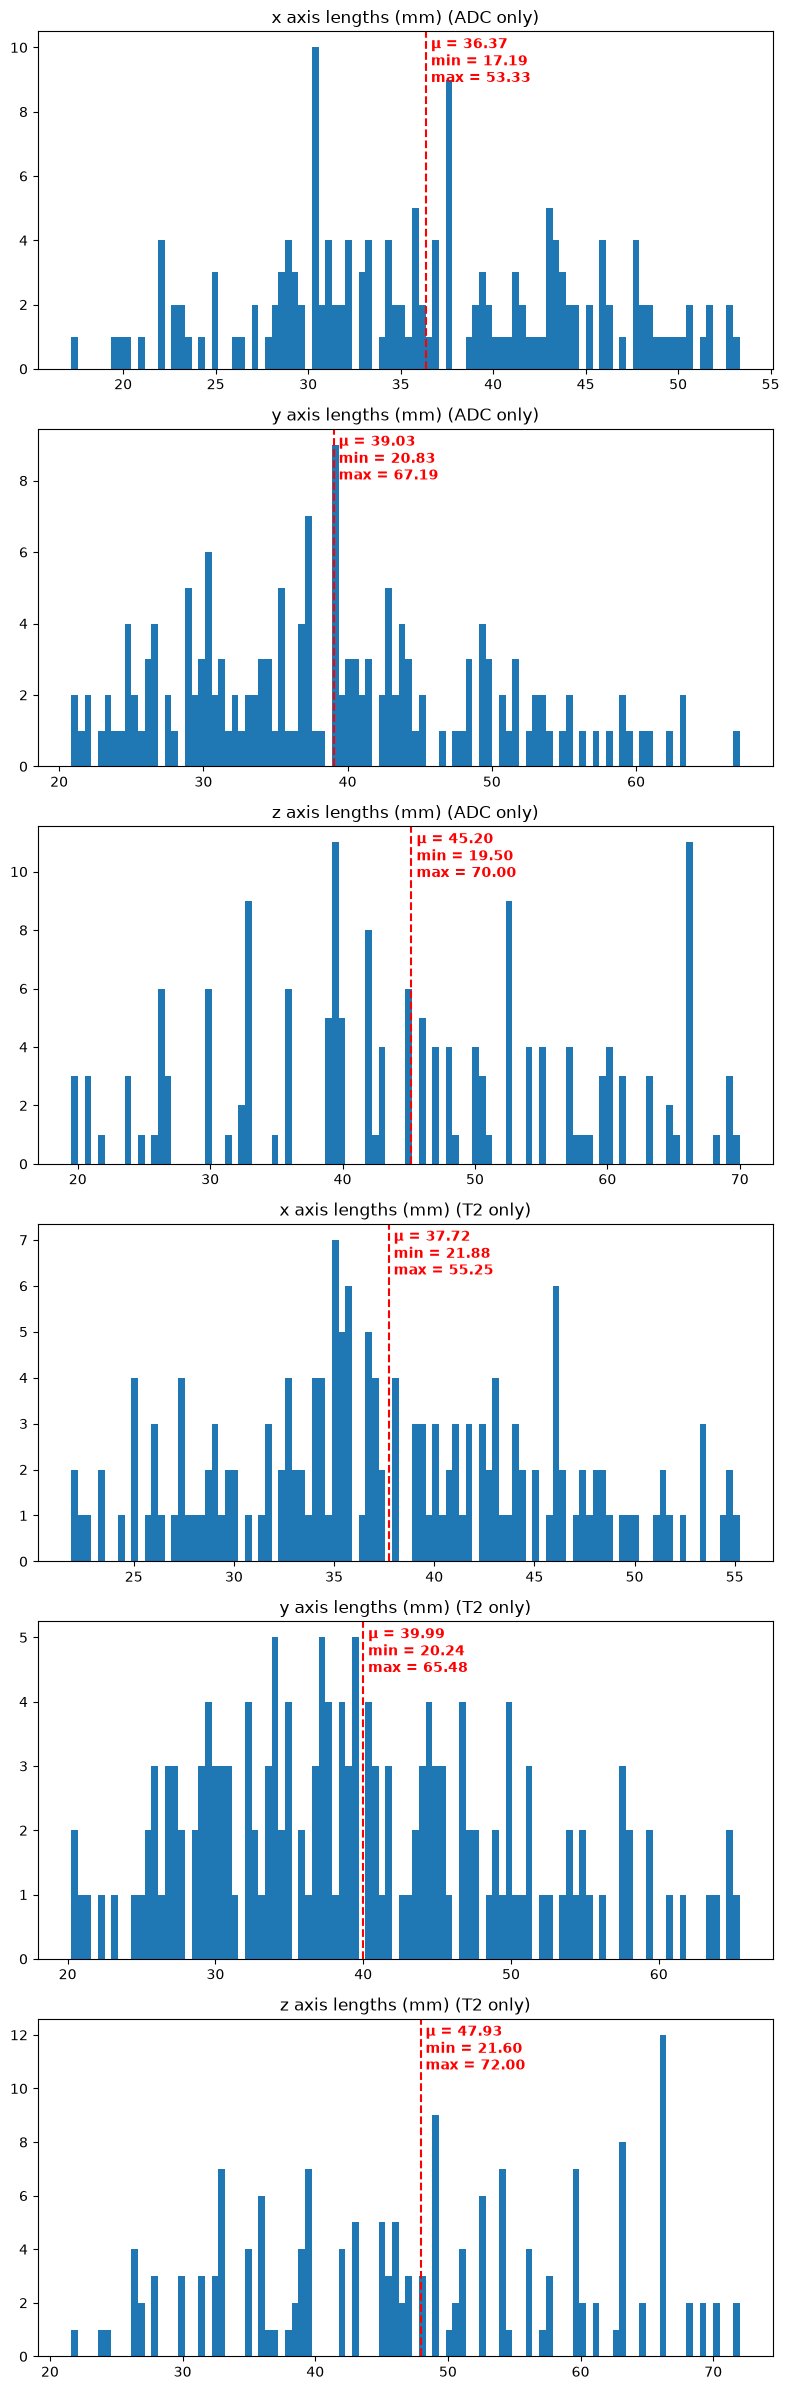

In [16]:
stats_tight_upper_df = plot_histograms(filter_interval=(0.025, 0.9))

In [18]:
all_stats_combined = pd.concat(
    [stats_all_df, stats_no_outliers_df, stats_tight_upper_df],
    axis=1,
    keys=["all", "filtered (p2.5 - p97.5)", "filtered (p2.5 - p90)"]
)
all_stats_combined

all                        filtered (p2.5 - p97.5)             \
            mean        min         max                 up_drop       mean   
ADC x  38.664543   9.375000   97.656250                     5.0  38.251895   
    y  42.774045  12.537280  131.249995                     5.0  41.805563   
    z  48.814527  14.399947  136.000004                     5.0  47.704671   
T2  x  39.774225  13.522728  103.125000                     5.0  39.353274   
    y  43.984015  14.880950  140.454547                     5.0  42.864116   
    z  50.801739  15.000000  147.000000                     5.0  50.109140   

                            filtered (p2.5 - p90)                        \
             min        max               up_drop       mean        min   
ADC x  17.187500  65.625000                  19.0  36.366352  17.187500   
    y  20.833333  83.928571                  19.0  39.029163  20.833333   
    z  19.500034  85.800000                  19.0  45.202629  19.500034   
T2  x  21.875000  62.840910                  19.0  37.724228  21.875000   
    y  20.238092  84.999998                  19.0  39.987629  20.238092   
    z  21.600020  84.000001                  19.0  47.934314  21.600020   

                  
             max  
ADC x  53.333332  
    y  67.187500  
    z  70.000001  
T2  x  55.251600  
    y  65.476180  
    z  71.999873

In [ ]:
# to keep as a reference
len(manifest_df)

376

When compared to 188 samples from each modality, having 10 of them dropped should not be a big deal. Of course we wont drop large volumes samples, but crop only center of them. This will affect model's prediction capacity on these samples of course, but overall, we will be able to have less computation burden, less tissue in sample and bigger batch size.

**Conclusion:** I think we can use max dimensions in p90 upper limit case, numbers rounded up:

- X dimension (mm) = 54
- Y dimension (mm) = 68
- Z dimension (mm) = 70

After resampling all samples, I will use the closest (round up or down) value which is a factor of the resampled dimension (thickness of the voxel, for that specific dimension)